In [1]:
import pandas as pd
import numpy as np
import pickle

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
%pip install seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
fake = pd.read_csv("Fake.csv")
true = pd.read_csv("True.csv")

print("Fake Dataset:")
print(fake.head())

print("\nTrue Dataset:")
print(true.head())

Fake Dataset:
                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text subject  \
0  Donald Trump just couldn t wish all Americans ...    News   
1  House Intelligence Committee Chairman Devin Nu...    News   
2  On Friday, it was revealed that former Milwauk...    News   
3  On Christmas day, Donald Trump announced that ...    News   
4  Pope Francis used his annual Christmas Day mes...    News   

                date  
0  December 31, 2017  
1  December 31, 2017  
2  December 30, 2017  
3  December 29, 2017  
4  December 25, 2017  

True Dataset:
                                               title  \
0  As U.S. budget fight looms, Republicans flip t...   

In [4]:
print("Fake Columns:", fake.columns.tolist())
print("True Columns:", true.columns.tolist())

print("Fake Shape:", fake.shape)
print("True Shape:", true.shape)

Fake Columns: ['title', 'text', 'subject', 'date']
True Columns: ['title', 'text', 'subject', 'date']
Fake Shape: (23481, 4)
True Shape: (21417, 4)


In [5]:
text_columns = ["title", "text", "content", "article", "news", "description"]

available_columns = [
    col for col in text_columns
    if col in fake.columns and col in true.columns
]

if not available_columns:
    raise ValueError("News text column nahi mila. Cell 3 ke columns check karo.")

print("Selected columns:", available_columns)

fake["label"] = 0
true["label"] = 1

data = pd.concat([fake, true], ignore_index=True)

data["news"] = data[available_columns].fillna("").astype(str).agg(" ".join, axis=1)

data = data[data["news"].str.strip() != ""]
data = data.drop_duplicates(subset=["news"])

print(data[["news", "label"]].head())
print(data["label"].value_counts())

Selected columns: ['title', 'text']
                                                news  label
0   Donald Trump Sends Out Embarrassing New Year’...      0
1   Drunk Bragging Trump Staffer Started Russian ...      0
2   Sheriff David Clarke Becomes An Internet Joke...      0
3   Trump Is So Obsessed He Even Has Obama’s Name...      0
4   Pope Francis Just Called Out Donald Trump Dur...      0
label
1    21197
0    17908
Name: count, dtype: int64


In [6]:
X = data["news"]
y = data["label"]

print("Total News:", len(X))
print("Fake News:", sum(y == 0))
print("Real News:", sum(y == 1))

Total News: 39105
Fake News: 17908
Real News: 21197


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 31284
Testing Data: 7821


In [8]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training Shape:", X_train_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)

Training Shape: (31284, 5000)
Testing Shape: (7821, 5000)


In [9]:
model = LinearSVC(random_state=42)

model.fit(X_train_tfidf, y_train)

print("Model Training Completed!")
print("Model Classes:", model.classes_)

Model Training Completed!
Model Classes: [0 1]


In [10]:
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fake News", "Real News"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 99.36069556322721 %

Classification Report:
              precision    recall  f1-score   support

   Fake News       1.00      0.99      0.99      3582
   Real News       0.99      1.00      0.99      4239

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821


Confusion Matrix:
[[3547   35]
 [  15 4224]]


In [11]:
saved_data = {
    "model": model,
    "tfidf": tfidf,
    "label_values": [0, 1]
}

with open("fake_news_model.pkl", "wb") as file:
    pickle.dump(saved_data, file)

print("Model successfully saved!")

Model successfully saved!


In [12]:
import pandas as pd

fake = pd.read_csv("Fake.csv")
true = pd.read_csv("True.csv")

fake['label'] = 0
true['label'] = 1

data = pd.concat([fake, true], axis=0)

data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print(data.head())
print(data.shape)

                                               title  \
0  Ben Stein Calls Out 9th Circuit Court: Committ...   
1  Trump drops Steve Bannon from National Securit...   
2  Puerto Rico expects U.S. to lift Jones Act shi...   
3   OOPS: Trump Just Accidentally Confirmed He Le...   
4  Donald Trump heads for Scotland to reopen a go...   

                                                text       subject  \
0  21st Century Wire says Ben Stein, reputable pr...       US_News   
1  WASHINGTON (Reuters) - U.S. President Donald T...  politicsNews   
2  (Reuters) - Puerto Rico Governor Ricardo Rosse...  politicsNews   
3  On Monday, Donald Trump once again embarrassed...          News   
4  GLASGOW, Scotland (Reuters) - Most U.S. presid...  politicsNews   

                  date  label  
0    February 13, 2017      0  
1       April 5, 2017       1  
2  September 27, 2017       1  
3         May 22, 2017      0  
4       June 24, 2016       1  
(44898, 5)


In [13]:
print("Fake and Real News Count:")
print(data['label'].value_counts())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Values:")
print(data.duplicated().sum())

Fake and Real News Count:
label
0    23481
1    21417
Name: count, dtype: int64

Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicate Values:
209


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    max_df=0.7
)

In [15]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training Shape:", X_train_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)

Training Shape: (31284, 108973)
Testing Shape: (7821, 108973)


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [17]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [18]:
y_pred = model.predict(X_test_tfidf)

print("Prediction Completed!")

Prediction Completed!


In [19]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 98.47845544048076 %


In [20]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3582
           1       0.98      0.99      0.99      4239

    accuracy                           0.98      7821
   macro avg       0.99      0.98      0.98      7821
weighted avg       0.98      0.98      0.98      7821



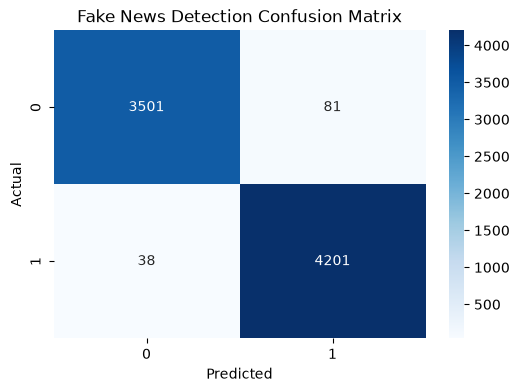

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fake News Detection Confusion Matrix")

plt.show()

In [22]:
import pickle

with open("fake_news_model.pkl", "wb") as file:
    pickle.dump({
        'model': model,
        'tfidf': tfidf
    }, file)

print("Model Saved Successfully!")

Model Saved Successfully!


In [23]:
import pickle

with open("fake_news_model.pkl", "wb") as file:
    pickle.dump({
        'model': model,
        'tfidf': tfidf
    }, file)

print("Model Saved Successfully!")

Model Saved Successfully!
